<a href="https://colab.research.google.com/github/Mant-0957/DeepLearning_PR3/blob/main/DeepLearning_PR3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CV PR 3 — Complete Computer Vision Project
**Topics:** Morphological Operations · Bitwise Operations · Histograms · YuNet Face Detection · YOLOv8 Object Detection

## Project objective
Build one beginner-friendly computer-vision notebook that moves from classical image processing to face detection and deep-learning object detection, then combines both detectors in a simple pipeline.


In [1]:
%pip install -q opencv-contrib-python==5.0.0.93 ultralytics matplotlib numpy pandas requests

In [2]:

import os
import time
import math
import requests
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from IPython.display import display

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data" / "images"
MODEL_DIR = BASE_DIR / "data" / "models"
PLOTS_DIR = BASE_DIR / "plots"

for folder in [DATA_DIR, MODEL_DIR, PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["font.size"] = 10


OpenCV version: 5.0.0
NumPy version: 2.1.3
Images folder: /content/data/images
Models folder: /content/data/models
Plots folder: /content/plots


In [3]:

IMAGE_URLS = {
    "lena": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg",
    "baboon": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/baboon.jpg",
    "fruits": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/fruits.jpg",
    "bus": "https://raw.githubusercontent.com/ultralytics/assets/main/im/bus.jpg",
    "zidane": "https://raw.githubusercontent.com/ultralytics/assets/main/im/zidane.jpg",
}


def download_file(url, destination):
    """Download one file. Return True when the file is available."""
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 1000:
        return True

    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        if len(response.content) < 1000:
            raise ValueError("Downloaded file is unexpectedly small.")
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(response.content)
        return True
    except Exception as error:
        print(f"Could not download {destination.name}: {error}")
        return False


for image_name, image_url in IMAGE_URLS.items():
    download_file(image_url, DATA_DIR / f"{image_name}.jpg")

EXTRA_IMAGES = {}

image_paths = {name: DATA_DIR / f"{name}.jpg" for name in IMAGE_URLS}
image_paths.update(EXTRA_IMAGES)

images = {}
for name, path in image_paths.items():
    image = cv2.imread(str(path))
    if image is not None:
        images[name] = image
        print(f"Loaded {name:10s} | shape={image.shape} | dtype={image.dtype}")
    else:
        print(f"Skipped {name}: image file was not found or could not be read.")

print("\nTotal real sample images loaded:", len(images))

Loaded lena       | shape=(512, 512, 3) | dtype=uint8
Loaded baboon     | shape=(512, 512, 3) | dtype=uint8
Loaded fruits     | shape=(480, 512, 3) | dtype=uint8
Loaded bus        | shape=(1080, 810, 3) | dtype=uint8
Loaded zidane     | shape=(720, 1280, 3) | dtype=uint8

Total real sample images loaded: 5


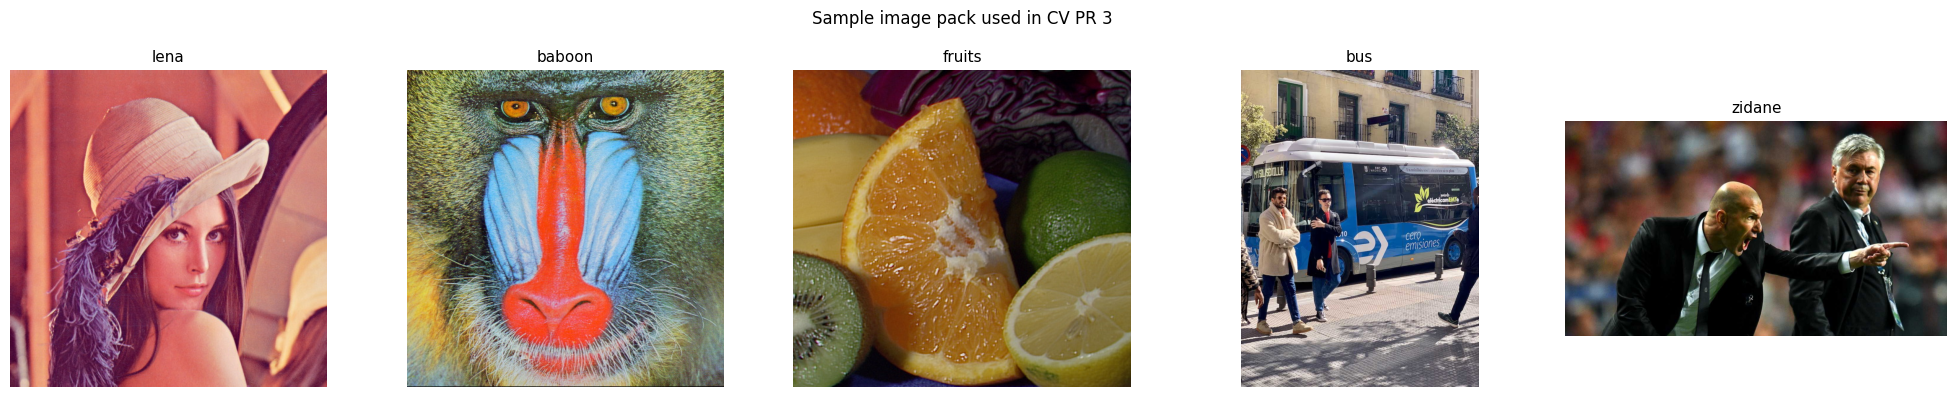

In [4]:
# A fallback image lets the classical image-processing sections run even if internet is unavailable.
def make_fallback_image(width=640, height=480):
    y, x = np.mgrid[0:height, 0:width]
    image = np.zeros((height, width, 3), dtype=np.uint8)
    image[:, :, 0] = (x * 255 / width).astype(np.uint8)
    image[:, :, 1] = (y * 255 / height).astype(np.uint8)
    image[:, :, 2] = ((x + y) * 255 / (width + height)).astype(np.uint8)
    cv2.circle(image, (190, 220), 90, (255, 255, 255), -1)
    cv2.rectangle(image, (340, 120), (540, 360), (30, 30, 30), -1)
    cv2.putText(image, "CV PR3", (185, 430), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 255, 255), 3)
    return image

if not images:
    images["generated"] = make_fallback_image()
    print("Using a generated fallback image for classical OpenCV sections.")


def show_image(image, title="Image", cmap=None, figsize=(6, 4)):
    """Display an image correctly in Jupyter (OpenCV uses BGR colour order)."""
    plt.figure(figsize=figsize)
    if image is None:
        plt.title(title + " (not available)")
        plt.axis("off")
    elif image.ndim == 2:
        plt.imshow(image, cmap=cmap or "gray")
        plt.title(title)
        plt.axis("off")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()


# Display a contact sheet of all sample images that were loaded.
fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
if len(images) == 1:
    axes = [axes]
for ax, (name, image) in zip(axes, images.items()):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")
plt.suptitle("Sample image pack used in CV PR 3")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "sample_image_pack.png", dpi=150, bbox_inches="tight")
plt.show()

# Task 1 — Environment Setup, Image I/O & Morphological Operations

**Objective:** Convert an image into a binary mask, then use erosion, dilation, opening, and closing to remove noise or repair small gaps.  
**Expected output:** Image information, a binary image, a 1 × 5 morphology comparison, and two 3 × 3 kernel-comparison grids.

Selected image: lena
Colour image shape: (512, 512, 3)
Colour image dtype: uint8
Gray image shape: (512, 512)
Gray image dtype: uint8


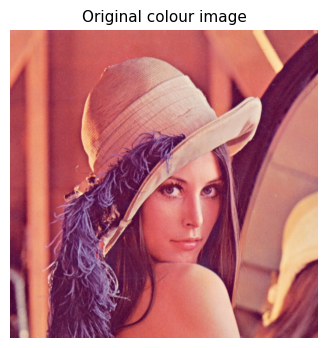

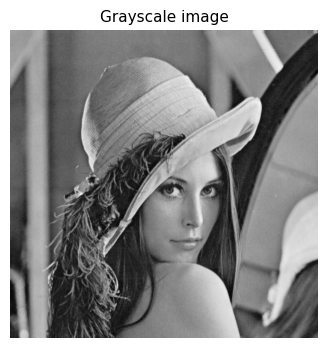

In [5]:
# Select a photo for image I/O. Prefer a face/photo example when available.
preferred_order = ["lena", "bus", "zidane", "fruits", "baboon"]
selected_name = next((name for name in preferred_order if name in images), next(iter(images)))
color_img = images[selected_name].copy()
gray_img = cv2.cvtColor(color_img, cv2.COLOR_BGR2GRAY)

print("Selected image:", selected_name)
print("Colour image shape:", color_img.shape)
print("Colour image dtype:", color_img.dtype)
print("Gray image shape:", gray_img.shape)
print("Gray image dtype:", gray_img.dtype)

show_image(color_img, "Original colour image")
show_image(gray_img, "Grayscale image")

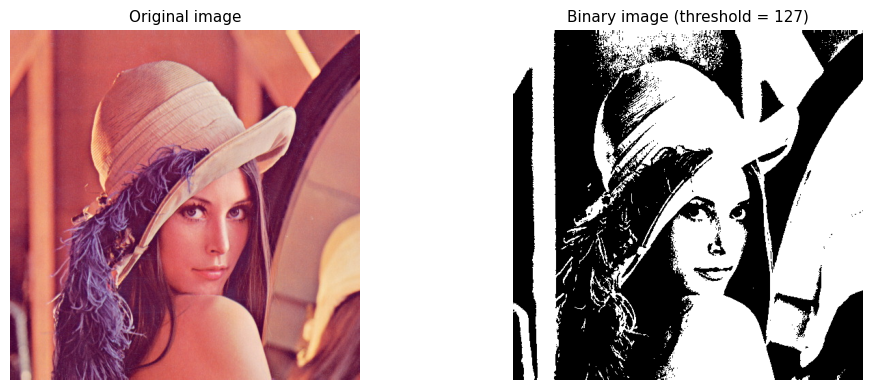

In [6]:
# Convert a real image to binary using the required threshold value.
_, binary_photo = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original image")
axes[1].imshow(binary_photo, cmap="gray")
axes[1].set_title("Binary image (threshold = 127)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "original_vs_binary.png", dpi=150, bbox_inches="tight")
plt.show()

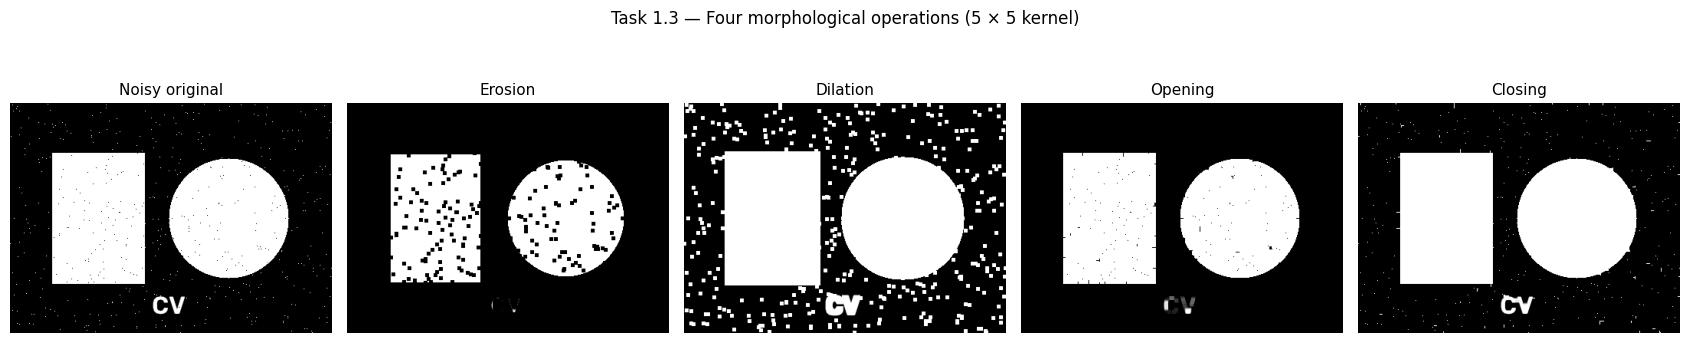

In [7]:
# Create a clear binary test mask with salt-and-pepper noise.
# This makes the effect of morphology easier to see than a thresholded photo alone.
rng = np.random.default_rng(42)
noisy_binary = np.zeros((300, 420), dtype=np.uint8)
cv2.rectangle(noisy_binary, (55, 65), (175, 235), 255, -1)
cv2.circle(noisy_binary, (285, 150), 78, 255, -1)
cv2.putText(noisy_binary, "CV", (185, 275), cv2.FONT_HERSHEY_SIMPLEX, 1.1, 255, 3)

# Add white dots (salt) and black dots (pepper).
num_noise = 1100
ys = rng.integers(0, noisy_binary.shape[0], num_noise)
xs = rng.integers(0, noisy_binary.shape[1], num_noise)
values = rng.choice([0, 255], size=num_noise)
noisy_binary[ys, xs] = values

kernel_5 = np.ones((5, 5), dtype=np.uint8)
eroded = cv2.erode(noisy_binary, kernel_5, iterations=1)
dilated = cv2.dilate(noisy_binary, kernel_5, iterations=1)
opened = cv2.morphologyEx(noisy_binary, cv2.MORPH_OPEN, kernel_5)
closed = cv2.morphologyEx(noisy_binary, cv2.MORPH_CLOSE, kernel_5)

results = [
    ("Noisy original", noisy_binary),
    ("Erosion", eroded),
    ("Dilation", dilated),
    ("Opening", opened),
    ("Closing", closed),
]
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, (title, image) in zip(axes, results):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.suptitle("Task 1.3 — Four morphological operations (5 × 5 kernel)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "morphology_operations.png", dpi=150, bbox_inches="tight")
plt.show()

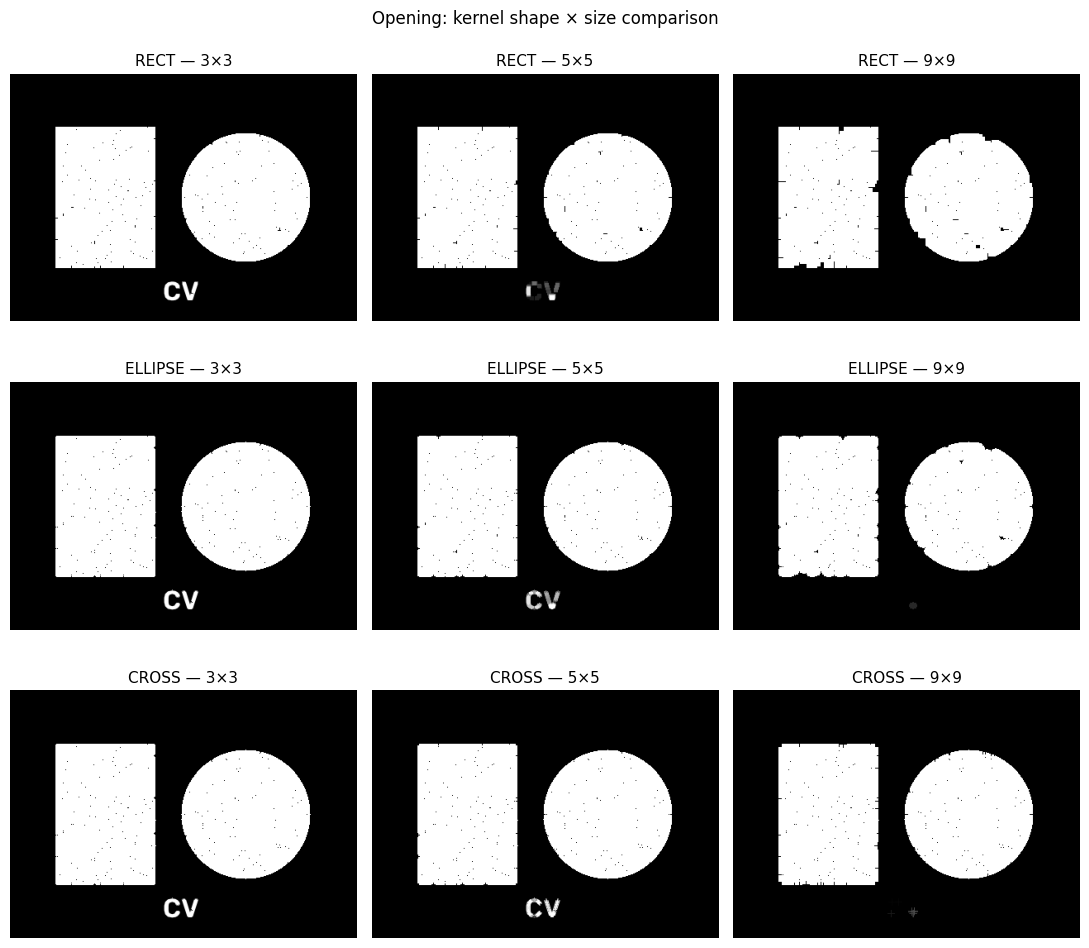

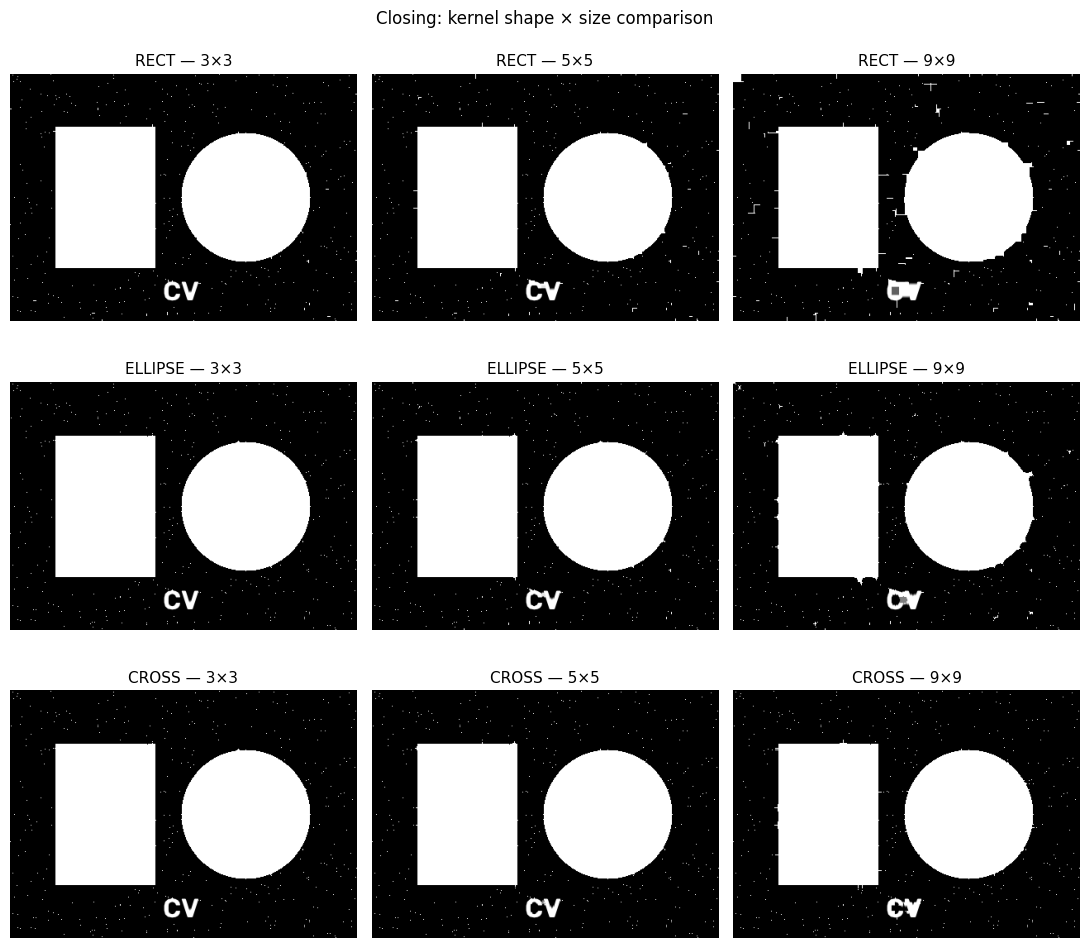

In [8]:
# Compare RECT, ELLIPSE and CROSS kernels at 3x3, 5x5 and 9x9.
# First grid: opening. Second grid: closing.
kernel_shapes = {
    "RECT": cv2.MORPH_RECT,
    "ELLIPSE": cv2.MORPH_ELLIPSE,
    "CROSS": cv2.MORPH_CROSS,
}
kernel_sizes = [3, 5, 9]

fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for row, (shape_name, shape_code) in enumerate(kernel_shapes.items()):
    for col, size in enumerate(kernel_sizes):
        kernel = cv2.getStructuringElement(shape_code, (size, size))
        output = cv2.morphologyEx(noisy_binary, cv2.MORPH_OPEN, kernel)
        axes[row, col].imshow(output, cmap="gray")
        axes[row, col].set_title(f"{shape_name} — {size}×{size}")
        axes[row, col].axis("off")
plt.suptitle("Opening: kernel shape × size comparison")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "morphology_opening_kernel_grid.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for row, (shape_name, shape_code) in enumerate(kernel_shapes.items()):
    for col, size in enumerate(kernel_sizes):
        kernel = cv2.getStructuringElement(shape_code, (size, size))
        output = cv2.morphologyEx(noisy_binary, cv2.MORPH_CLOSE, kernel)
        axes[row, col].imshow(output, cmap="gray")
        axes[row, col].set_title(f"{shape_name} — {size}×{size}")
        axes[row, col].axis("off")
plt.suptitle("Closing: kernel shape × size comparison")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "morphology_closing_kernel_grid.png", dpi=150, bbox_inches="tight")
plt.show()

### Task 1.5 — Why morphology works

- **Erosion** behaves like a local minimum filter on a binary image. It shrinks white regions and removes tiny bright specks. Use it when a foreground mask contains small white noise, but avoid a large kernel when thin object parts must be preserved.
- **Dilation** behaves like a local maximum filter. It expands white regions and fills tiny dark gaps. Use it to connect broken foreground strokes or make a detected region slightly larger.
- **Opening = erosion → dilation.** It removes small bright noise while largely preserving the size of larger foreground objects. Example: clean isolated white specks from a thresholded inspection mask before measuring an object.
- **Closing = dilation → erosion.** It fills small dark holes and narrow gaps while largely preserving the outside shape. Example: close small breaks in a character or road mask before contour detection.


# Task 2 — Bitwise Operations & Image Histograms

**Objective:** Use binary masks to select and combine image regions, then inspect intensity distributions and the effects of brightness/contrast changes.  
**Expected output:** A 2 × 3 bitwise grid, masked-photo examples, grayscale and B/G/R histograms, and three brightness/contrast comparisons with histograms.

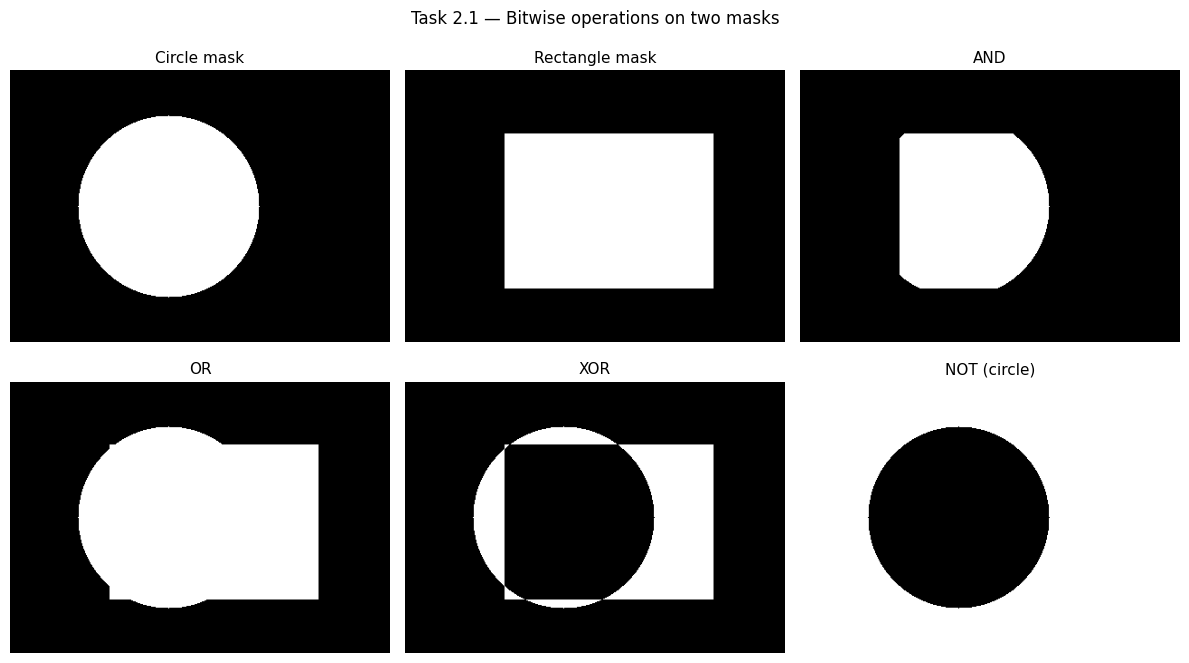

In [9]:
# Create two binary masks on black canvases.
mask_size = (300, 420)
mask_circle = np.zeros(mask_size, dtype=np.uint8)
mask_rectangle = np.zeros(mask_size, dtype=np.uint8)

cv2.circle(mask_circle, (175, 150), 100, 255, -1)
cv2.rectangle(mask_rectangle, (110, 70), (340, 240), 255, -1)

bitwise_and = cv2.bitwise_and(mask_circle, mask_rectangle)
bitwise_or = cv2.bitwise_or(mask_circle, mask_rectangle)
bitwise_xor = cv2.bitwise_xor(mask_circle, mask_rectangle)
bitwise_not = cv2.bitwise_not(mask_circle)

bitwise_images = [
    ("Circle mask", mask_circle),
    ("Rectangle mask", mask_rectangle),
    ("AND", bitwise_and),
    ("OR", bitwise_or),
    ("XOR", bitwise_xor),
    ("NOT (circle)", bitwise_not),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (title, image) in zip(axes.ravel(), bitwise_images):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.suptitle("Task 2.1 — Bitwise operations on two masks")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "bitwise_operations.png", dpi=150, bbox_inches="tight")
plt.show()

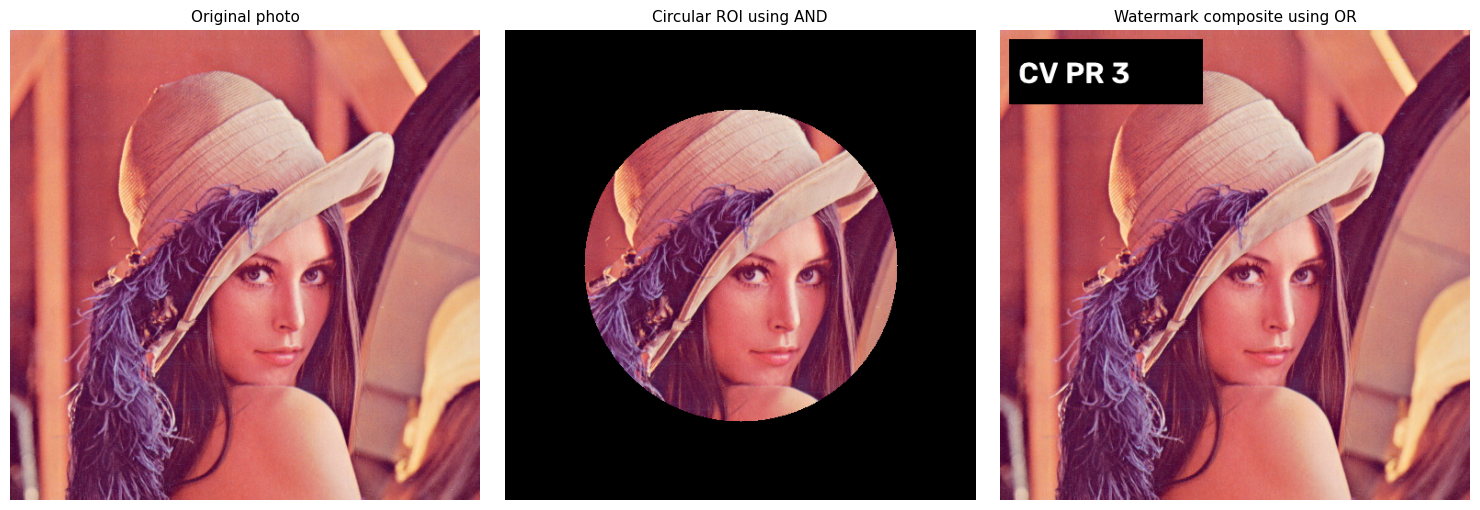

In [10]:
# Applied use-case 1: crop a circular region of interest (ROI) from a real photo.
photo = color_img.copy()
height, width = photo.shape[:2]
roi_mask = np.zeros((height, width), dtype=np.uint8)
center = (width // 2, height // 2)
radius = max(20, min(width, height) // 3)
cv2.circle(roi_mask, center, radius, 255, -1)
roi_only = cv2.bitwise_and(photo, photo, mask=roi_mask)

# Applied use-case 2: put a small simple watermark on the photo using bitwise OR.
logo = np.zeros_like(photo)
logo_mask = np.zeros((height, width), dtype=np.uint8)
logo_width = min(210, width - 20)
logo_height = min(70, height - 20)
cv2.rectangle(logo_mask, (10, 10), (10 + logo_width, 10 + logo_height), 255, -1)
cv2.putText(logo, "CV PR 3", (20, min(58, logo_height - 5)), cv2.FONT_HERSHEY_SIMPLEX,
            1.1, (255, 255, 255), 2, cv2.LINE_AA)
logo_part = cv2.bitwise_and(logo, logo, mask=logo_mask)
background_part = cv2.bitwise_and(photo, photo, mask=cv2.bitwise_not(logo_mask))
watermarked = cv2.bitwise_or(background_part, logo_part)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [photo, roi_only, watermarked],
                          ["Original photo", "Circular ROI using AND", "Watermark composite using OR"]):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "masked_overlay_usecase.png", dpi=150, bbox_inches="tight")
plt.show()

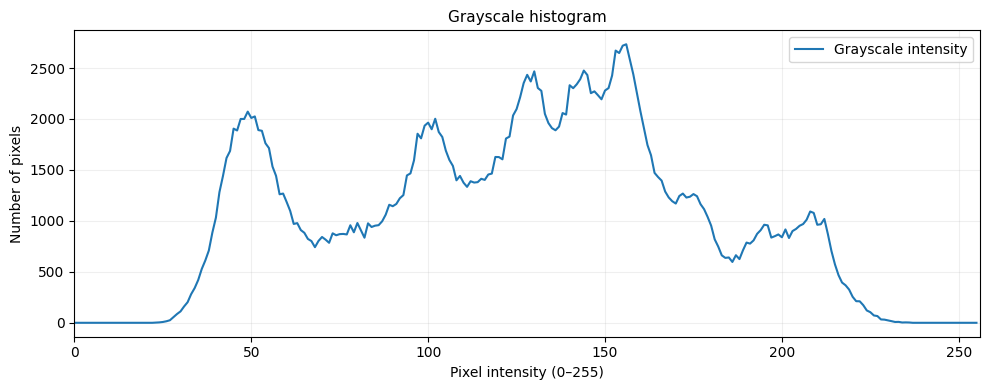

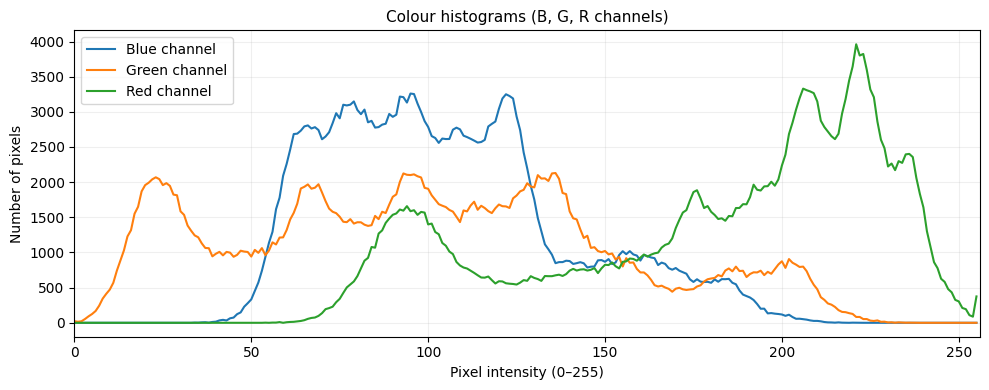

In [11]:
# Grayscale histogram.
gray_hist = cv2.calcHist([gray_img], [0], None, [256], [0, 256])
plt.figure(figsize=(10, 4))
plt.plot(gray_hist, label="Grayscale intensity")
plt.title("Grayscale histogram")
plt.xlabel("Pixel intensity (0–255)")
plt.ylabel("Number of pixels")
plt.xlim([0, 256])
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "grayscale_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

# Colour histograms: OpenCV stores channels as B, G, R.
channel_names = [(0, "Blue"), (1, "Green"), (2, "Red")]
plt.figure(figsize=(10, 4))
for channel, name in channel_names:
    hist = cv2.calcHist([color_img], [channel], None, [256], [0, 256])
    plt.plot(hist, label=f"{name} channel")
plt.title("Colour histograms (B, G, R channels)")
plt.xlabel("Pixel intensity (0–255)")
plt.ylabel("Number of pixels")
plt.xlim([0, 256])
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "colour_histogram_bgr.png", dpi=150, bbox_inches="tight")
plt.show()

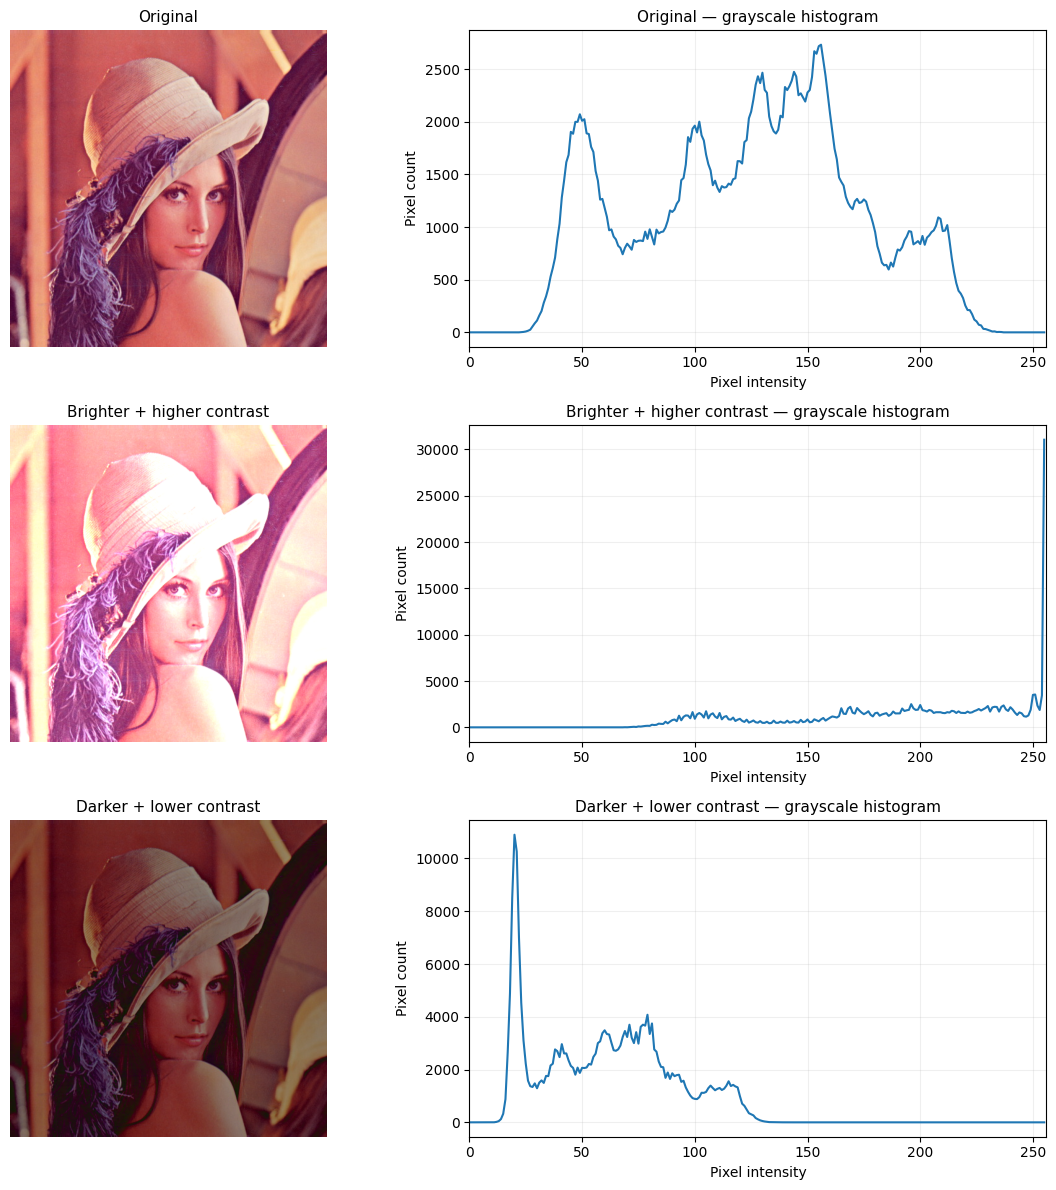

In [12]:
# Adjust brightness and contrast using the required convertScaleAbs function.
bright_img = cv2.convertScaleAbs(color_img, alpha=1.5, beta=30)
dark_img = cv2.convertScaleAbs(color_img, alpha=0.7, beta=-30)

versions = [
    ("Original", color_img),
    ("Brighter + higher contrast", bright_img),
    ("Darker + lower contrast", dark_img),
]
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for row, (title, image) in enumerate(versions):
    gray_version = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    hist = cv2.calcHist([gray_version], [0], None, [256], [0, 256])
    axes[row, 0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(title)
    axes[row, 0].axis("off")
    axes[row, 1].plot(hist)
    axes[row, 1].set_title(title + " — grayscale histogram")
    axes[row, 1].set_xlabel("Pixel intensity")
    axes[row, 1].set_ylabel("Pixel count")
    axes[row, 1].set_xlim(0, 256)
    axes[row, 1].grid(alpha=0.2)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "histogram_brightness_contrast.png", dpi=150, bbox_inches="tight")
plt.show()

### Task 2.5 — Why alpha, beta and histograms matter

The brightness/contrast formula is:

\[
\text{new pixel} = \alpha \times \text{old pixel} + \beta
\]

- **Alpha (contrast gain):** values above 1 spread intensity differences and increase contrast; values between 0 and 1 compress the range and reduce contrast.
- **Beta (brightness offset):** positive beta shifts intensities brighter; negative beta shifts them darker. OpenCV clips final values into the valid 0–255 range.
- A narrow histogram often indicates low contrast. A large number of values piled near 0 or 255 can indicate under-exposure or over-exposure/clipping.

Before face or object detection, histograms help identify whether a photo is unusually dark, bright, or low-contrast. They do not automatically fix the image, but they help decide whether gentle pre-processing is worth testing. Always compare detector results before and after an adjustment because aggressive changes can remove useful details.

# Task 3 — Face Detection with YuNet

**Objective:** Load the pretrained YuNet face detector, detect faces and five facial landmarks in multiple images, compare confidence thresholds, blur faces for privacy, and provide an optional webcam demo.  
**Expected output:** Annotated face images, a threshold table, a privacy-blurred image, and webcam FPS when a camera is available.

In [13]:
# Download the pretrained YuNet ONNX model from the OpenCV Zoo mirror.
YUNET_MODEL_PATH = MODEL_DIR / "face_detection_yunet_2023mar.onnx"
YUNET_MODEL_URL = (
    "https://huggingface.co/opencv/opencv_zoo/resolve/main/"
    "models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
)
model_downloaded = download_file(YUNET_MODEL_URL, YUNET_MODEL_PATH)
print("YuNet model available:", model_downloaded and YUNET_MODEL_PATH.exists())

YuNet model available: True


In [14]:
# Create YuNet detector. A fixed 320x320 input is used for this model file;
# detection boxes and landmarks are scaled back to the original image size.
def create_yunet_detector(score_threshold=0.7):
    if not YUNET_MODEL_PATH.exists():
        raise FileNotFoundError("YuNet model was not downloaded. Check your internet connection.")

    creator = getattr(cv2, "FaceDetectorYN_create", None)
    if creator is not None:
        return creator(str(YUNET_MODEL_PATH), "", (320, 320),
                       float(score_threshold), 0.3, 5000)
    # Alternate API spelling available in some OpenCV builds.
    return cv2.FaceDetectorYN.create(str(YUNET_MODEL_PATH), "", (320, 320),
                                     float(score_threshold), 0.3, 5000)


def detect_yunet_faces(image, detector):
    """Return face rows in original-image coordinates."""
    original_h, original_w = image.shape[:2]
    resized = cv2.resize(image, (320, 320))
    _, faces = detector.detect(resized)
    if faces is None:
        return np.empty((0, 15), dtype=np.float32)

    faces = faces.copy()
    scale_x = original_w / 320.0
    scale_y = original_h / 320.0
    faces[:, 0] *= scale_x  # x
    faces[:, 1] *= scale_y  # y
    faces[:, 2] *= scale_x  # width
    faces[:, 3] *= scale_y  # height
    # Five landmark coordinate pairs start at column 4.
    for point_index in range(5):
        faces[:, 4 + 2 * point_index] *= scale_x
        faces[:, 5 + 2 * point_index] *= scale_y
    return faces


def draw_yunet_faces(image, faces, box_color=(0, 255, 0)):
    output = image.copy()
    landmark_colors = [(255, 0, 0), (0, 0, 255), (0, 255, 0), (255, 0, 255), (0, 255, 255)]
    for face in faces:
        x, y, w, h = face[:4].astype(int)
        score = float(face[-1])
        cv2.rectangle(output, (x, y), (x + w, y + h), box_color, 2)
        cv2.putText(output, f"Face {score:.2f}", (x, max(20, y - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, box_color, 2)
        for point_index, color in enumerate(landmark_colors):
            px = int(face[4 + 2 * point_index])
            py = int(face[5 + 2 * point_index])
            cv2.circle(output, (px, py), 3, color, -1)
    return output

print("YuNet helper functions are ready.")

YuNet helper functions are ready.


lena: 1 face(s)
bus: 2 face(s)
zidane: 2 face(s)


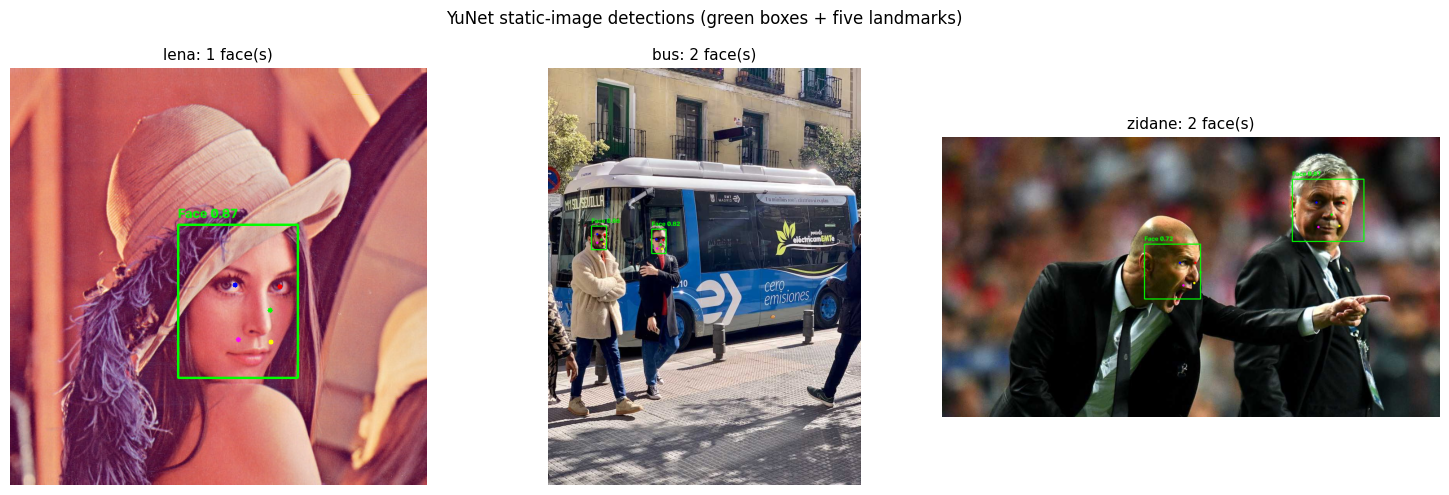

In [15]:
# Run YuNet on multiple available photos. Bus and Zidane offer more varied people/poses
# than a single portrait. Add your own side-profile or sunglasses photo to data/images
# for an even stronger test.
face_test_names = [name for name in ["lena", "bus", "zidane"] if name in images]
if not face_test_names:
    face_test_names = [selected_name]

face_detector = create_yunet_detector(score_threshold=0.7)
face_results = {}
fig, axes = plt.subplots(1, len(face_test_names), figsize=(5 * len(face_test_names), 5))
if len(face_test_names) == 1:
    axes = [axes]
for ax, name in zip(axes, face_test_names):
    source = images[name]
    faces = detect_yunet_faces(source, face_detector)
    face_results[name] = faces
    annotated = draw_yunet_faces(source, faces)
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}: {len(faces)} face(s)")
    ax.axis("off")
    print(f"{name}: {len(faces)} face(s)")
plt.suptitle("YuNet static-image detections (green boxes + five landmarks)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "face_detection_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

,Image,Score threshold,Detected faces
0,lena,0.5,1
1,bus,0.5,2
2,zidane,0.5,2
3,lena,0.7,1
4,bus,0.7,2
5,zidane,0.7,2
6,lena,0.9,0
7,bus,0.9,0
8,zidane,0.9,0


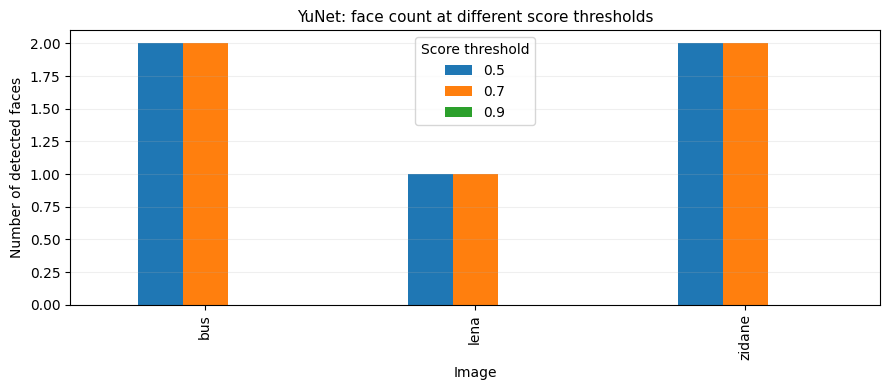

In [16]:
# Score-threshold experiment: compare detected face counts at 0.5, 0.7 and 0.9.
threshold_rows = []
for threshold in [0.5, 0.7, 0.9]:
    detector = create_yunet_detector(score_threshold=threshold)
    for name in face_test_names:
        found_faces = detect_yunet_faces(images[name], detector)
        threshold_rows.append({
            "Image": name,
            "Score threshold": threshold,
            "Detected faces": len(found_faces),
        })

yunet_threshold_df = pd.DataFrame(threshold_rows)
display(yunet_threshold_df)

threshold_pivot = yunet_threshold_df.pivot(index="Image", columns="Score threshold", values="Detected faces")
ax = threshold_pivot.plot(kind="bar", figsize=(9, 4))
ax.set_title("YuNet: face count at different score thresholds")
ax.set_xlabel("Image")
ax.set_ylabel("Number of detected faces")
ax.legend(title="Score threshold")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "yunet_threshold_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

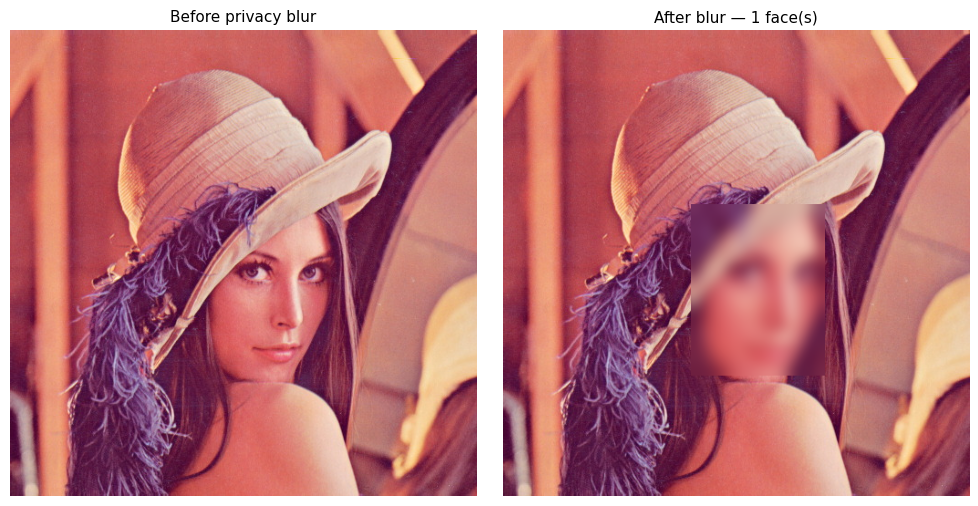

In [17]:
# Privacy use-case: blur only the face regions detected in one photo.
privacy_name = face_test_names[0]
privacy_image = images[privacy_name].copy()
privacy_detector = create_yunet_detector(score_threshold=0.5)
privacy_faces = detect_yunet_faces(privacy_image, privacy_detector)
blurred_image = privacy_image.copy()

for face in privacy_faces:
    x, y, w, h = face[:4].astype(int)
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(blurred_image.shape[1], x + w), min(blurred_image.shape[0], y + h)
    if x2 > x1 and y2 > y1:
        face_crop = blurred_image[y1:y2, x1:x2]
        k = max(15, (min(face_crop.shape[:2]) // 3) | 1)  # odd blur kernel
        blurred_image[y1:y2, x1:x2] = cv2.GaussianBlur(face_crop, (k, k), 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(privacy_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Before privacy blur")
axes[1].imshow(cv2.cvtColor(blurred_image, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"After blur — {len(privacy_faces)} face(s)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "face_privacy_blur.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# Optional real-time YuNet webcam demo.
# Set RUN_WEBCAM = True when running locally with a webcam and OpenCV GUI support.
def run_yunet_webcam(max_seconds=20):
    detector = create_yunet_detector(score_threshold=0.7)
    camera = cv2.VideoCapture(0)
    if not camera.isOpened():
        print("Webcam not available. Skipping live YuNet demo.")
        return None

    frame_count = 0
    start_time = time.perf_counter()
    print("Press q to stop the webcam window.")
    try:
        while time.perf_counter() - start_time < max_seconds:
            ok, frame = camera.read()
            if not ok:
                break
            faces = detect_yunet_faces(frame, detector)
            output = draw_yunet_faces(frame, faces)
            frame_count += 1
            elapsed = max(time.perf_counter() - start_time, 1e-6)
            fps = frame_count / elapsed
            cv2.putText(output, f"YuNet FPS: {fps:.1f}", (15, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
            cv2.imshow("YuNet Face Detection — press q to quit", output)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    except cv2.error as error:
        print("OpenCV display is not supported in this notebook environment:", error)
    finally:
        camera.release()
        cv2.destroyAllWindows()

    elapsed = max(time.perf_counter() - start_time, 1e-6)
    fps = frame_count / elapsed
    print(f"YuNet webcam: {frame_count} frames in {elapsed:.2f}s = {fps:.2f} FPS")
    return fps

RUN_WEBCAM = False
if RUN_WEBCAM:
    yunet_webcam_fps = run_yunet_webcam(max_seconds=20)
else:
    print("Webcam demo is ready. Set RUN_WEBCAM = True to start it.")

Webcam demo is ready. Set RUN_WEBCAM = True to start it.


### Task 3.5 — Why YuNet?

YuNet is a compact CNN-based face detector from the OpenCV Zoo. It returns a face bounding box, five facial landmark points (eyes, nose, and mouth corners), and a confidence score in one detection pass. It is designed to be lightweight, so it is useful when a small face detector is needed in an OpenCV pipeline.

The **score threshold** controls how confident a detection must be before it is kept. A lower value can find more difficult faces but may also keep false positives. A higher value is more selective but can miss small, blurry, turned, or partly hidden faces. For a real-time security camera, a moderate threshold (for example 0.5–0.7) can be a starting point, followed by testing on the real camera. For offline photo tagging, a higher threshold (for example 0.7–0.9) may reduce false detections. The correct value depends on the scene and should be validated.

**Image note:** The notebook tests several available example photos. For the assignment's side-profile and sunglasses/partial-occlusion requirement, add at least one real side-profile photo and one real partially occluded/sunglasses photo to `data/images`, then include their names in `face_test_names`. An artificially covered face is not a substitute for a real side-profile test.

# Task 4 — Object Detection with YOLOv8

**Objective:** Use pretrained YOLOv8n weights to locate multiple everyday object classes, explore confidence and IoU settings, and count detections by class.  
**Expected output:** Annotated object-detection photos, an optional webcam demo with FPS, a 3 × 3 threshold experiment, and a per-class bar chart.

In [19]:
# Load pretrained YOLOv8 Nano. Ultralytics downloads yolov8n.pt automatically on first use.
from ultralytics import YOLO

yolo_model = YOLO("yolov8n.pt")
print("YOLOv8n model loaded successfully.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv8n model loaded successfully.


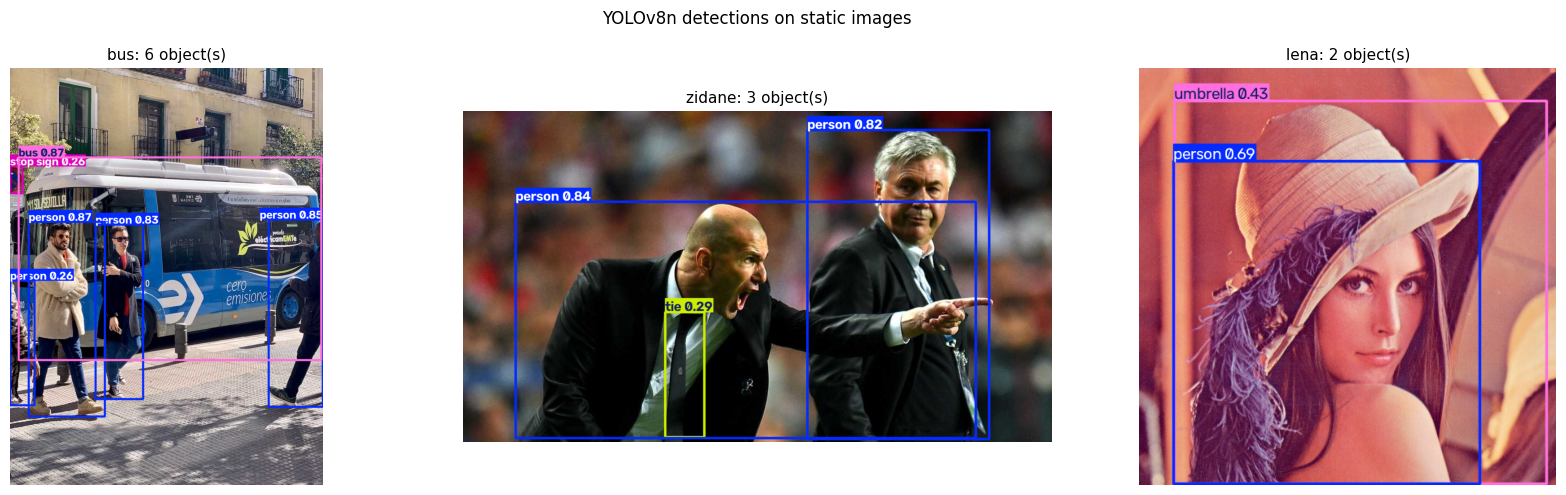

bus: 6 detections
zidane: 3 detections
lena: 2 detections


In [20]:
# Run YOLO on 2–3 sample photos containing common objects.
yolo_test_names = [name for name in ["bus", "zidane", "lena"] if name in images]
if not yolo_test_names:
    yolo_test_names = [selected_name]

static_yolo_results = {}
fig, axes = plt.subplots(1, len(yolo_test_names), figsize=(6 * len(yolo_test_names), 5))
if len(yolo_test_names) == 1:
    axes = [axes]
for ax, name in zip(axes, yolo_test_names):
    result = yolo_model.predict(images[name], conf=0.25, iou=0.5, verbose=False)[0]
    static_yolo_results[name] = result
    annotated = result.plot()  # Ultralytics returns a BGR image
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    count = 0 if result.boxes is None else len(result.boxes)
    ax.set_title(f"{name}: {count} object(s)")
    ax.axis("off")
plt.suptitle("YOLOv8n detections on static images")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "yolo_detections.png", dpi=150, bbox_inches="tight")
plt.show()

for name, result in static_yolo_results.items():
    print(f"{name}: {0 if result.boxes is None else len(result.boxes)} detections")

In [21]:
# Optional real-time YOLO webcam demo.
def run_yolo_webcam(max_seconds=20):
    camera = cv2.VideoCapture(0)
    if not camera.isOpened():
        print("Webcam not available. Skipping live YOLO demo.")
        return None

    frame_count = 0
    start_time = time.perf_counter()
    print("Press q to stop the webcam window.")
    try:
        while time.perf_counter() - start_time < max_seconds:
            ok, frame = camera.read()
            if not ok:
                break
            result = yolo_model.predict(frame, conf=0.25, iou=0.5, verbose=False)[0]
            output = result.plot()
            frame_count += 1
            elapsed = max(time.perf_counter() - start_time, 1e-6)
            fps = frame_count / elapsed
            cv2.putText(output, f"YOLO FPS: {fps:.1f}", (15, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
            cv2.imshow("YOLOv8 Object Detection — press q to quit", output)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    except cv2.error as error:
        print("OpenCV display is not supported in this notebook environment:", error)
    finally:
        camera.release()
        cv2.destroyAllWindows()

    elapsed = max(time.perf_counter() - start_time, 1e-6)
    fps = frame_count / elapsed
    print(f"YOLO webcam: {frame_count} frames in {elapsed:.2f}s = {fps:.2f} FPS")
    return fps

RUN_WEBCAM = False
if RUN_WEBCAM:
    yolo_webcam_fps = run_yolo_webcam(max_seconds=20)
else:
    print("Webcam demo is ready. Set RUN_WEBCAM = True to start it.")

Webcam demo is ready. Set RUN_WEBCAM = True to start it.


,Confidence,IoU,Retained boxes
0,0.25,0.3,6
1,0.25,0.5,6
2,0.25,0.7,6
3,0.50,0.3,4
4,0.50,0.5,4
5,0.50,0.7,4
6,0.75,0.3,4
7,0.75,0.5,4
8,0.75,0.7,4


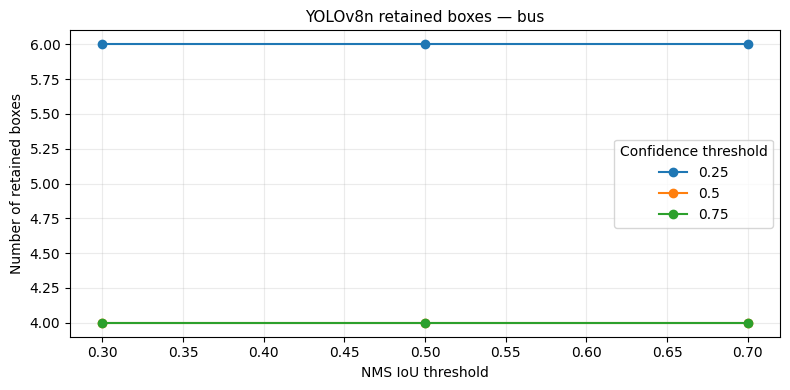

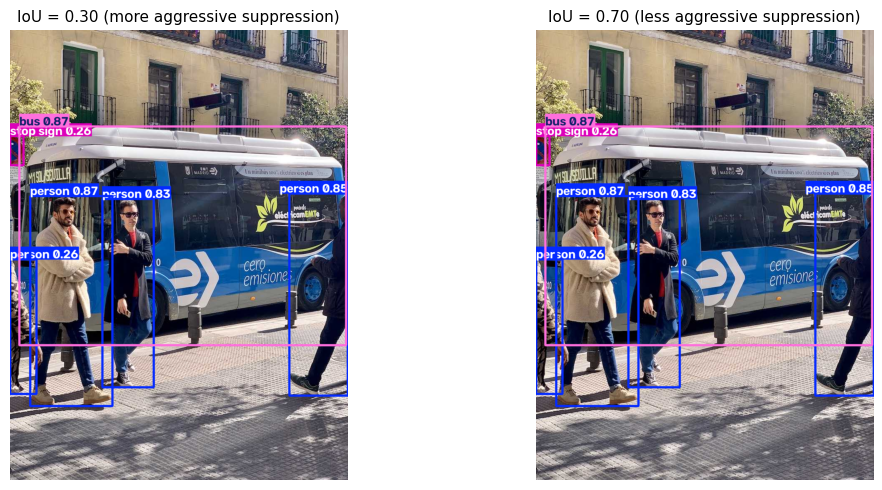

In [22]:
# Explore confidence and IoU settings on one image with multiple objects.
tuning_name = "bus" if "bus" in images else yolo_test_names[0]
tuning_image = images[tuning_name]
confidence_values = [0.25, 0.50, 0.75]
iou_values = [0.30, 0.50, 0.70]
tuning_rows = []
tuning_results = {}

for conf_value in confidence_values:
    for iou_value in iou_values:
        result = yolo_model.predict(tuning_image, conf=conf_value, iou=iou_value, verbose=False)[0]
        box_count = 0 if result.boxes is None else len(result.boxes)
        tuning_rows.append({
            "Confidence": conf_value,
            "IoU": iou_value,
            "Retained boxes": box_count,
        })
        tuning_results[(conf_value, iou_value)] = result

yolo_tuning_df = pd.DataFrame(tuning_rows)
display(yolo_tuning_df)

pivot = yolo_tuning_df.pivot(index="IoU", columns="Confidence", values="Retained boxes")
ax = pivot.plot(marker="o", figsize=(8, 4))
ax.set_title(f"YOLOv8n retained boxes — {tuning_name}")
ax.set_xlabel("NMS IoU threshold")
ax.set_ylabel("Number of retained boxes")
ax.legend(title="Confidence threshold")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "yolo_confidence_iou_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

# Compare two NMS IoU outputs visually at the same confidence level.
low_iou_result = tuning_results[(0.25, 0.30)]
high_iou_result = tuning_results[(0.25, 0.70)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, result, title in zip(axes, [low_iou_result, high_iou_result],
                             ["IoU = 0.30 (more aggressive suppression)",
                              "IoU = 0.70 (less aggressive suppression)"]):
    ax.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "yolo_nms_iou_visual_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Important IoU / Non-Maximum Suppression (NMS) clarification

The project brief asks for an example of duplicate boxes at a low IoU setting. In standard YOLO NMS, the usual direction is the opposite: **a lower IoU threshold suppresses overlapping boxes more aggressively**, while a higher IoU threshold can allow more overlapping boxes to remain. The two images above demonstrate the direction on the selected sample. Whether visible duplicate boxes actually occur depends on the model output and the photo; do not claim duplicates if the selected image does not show them.

- **Confidence threshold** removes predictions below the chosen confidence. Increasing it usually reduces the number of retained detections.
- **NMS IoU threshold** controls how much overlap is tolerated between boxes before one is suppressed. It does not mean the model is more accurate just because the number of boxes changes.

,COCO class,Detection count
0,person,7
1,bus,1
2,stop sign,1
3,tie,1
4,umbrella,1


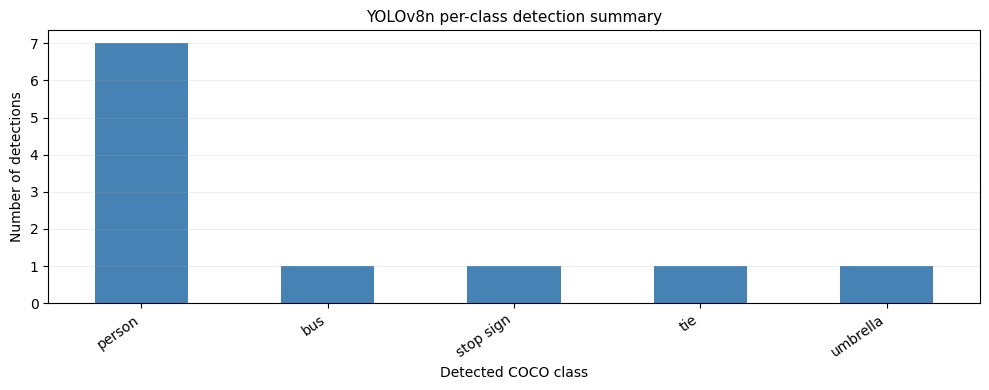

In [23]:
# Count the classes detected across all static test images.
class_counts = Counter()
for name, result in static_yolo_results.items():
    if result.boxes is None:
        continue
    for class_id in result.boxes.cls.cpu().numpy().astype(int):
        class_name = result.names[int(class_id)]
        class_counts[class_name] += 1

class_summary_df = pd.DataFrame(
    sorted(class_counts.items(), key=lambda item: item[1], reverse=True),
    columns=["COCO class", "Detection count"]
)
display(class_summary_df)

if not class_summary_df.empty:
    ax = class_summary_df.plot(x="COCO class", y="Detection count", kind="bar",
                               legend=False, figsize=(10, 4), color="steelblue")
    ax.set_title("YOLOv8n per-class detection summary")
    ax.set_xlabel("Detected COCO class")
    ax.set_ylabel("Number of detections")
    ax.grid(axis="y", alpha=0.2)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "yolo_per_class_summary.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No objects were detected in the available sample images.")

### Task 4.5 — Why YOLO generalises

YOLO is a **single-stage object detector**: it predicts bounding boxes and class scores directly in one forward pass, then applies Non-Maximum Suppression to remove duplicate overlapping detections. The pretrained COCO model has learned visual features for 80 everyday object classes, so it can predict those classes without a separate hand-written detector for each one.

`yolov8n.pt` is the nano model. It is small and usually faster on CPU/edge hardware, but larger variants such as `yolov8s`, `yolov8m`, `yolov8l`, and `yolov8x` can provide higher accuracy at greater compute and memory cost. The right model depends on the hardware and the required accuracy. Small objects, occlusion, motion blur, low light, and unusual camera angles can still cause missed or incorrect classes.

# Task 5 — Integrated Pipeline & Final Comparison

**Objective:** Put YuNet and YOLO on the same frame, test optional morphology pre-cleaning, and compare speed using the same 100-frame sample.  
**Expected output:** One combined annotated frame, a pre-cleaning comparison, an FPS bar chart, and a final technique comparison table.

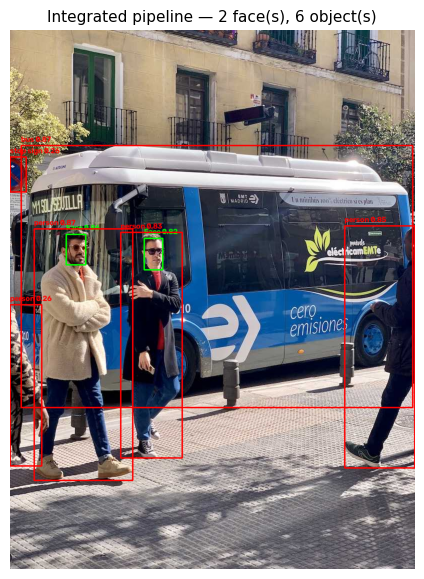

True

In [24]:
# Integrate both detectors on one image. YuNet face boxes are green; YOLO object boxes are red.
def integrated_detection(frame, yunet_detector=None, confidence=0.25, iou=0.5):
    if yunet_detector is None:
        yunet_detector = create_yunet_detector(score_threshold=0.7)

    output = frame.copy()

    # First layer: YuNet faces (green).
    faces = detect_yunet_faces(frame, yunet_detector)
    for face in faces:
        x, y, w, h = face[:4].astype(int)
        cv2.rectangle(output, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(output, f"Face {float(face[-1]):.2f}", (x, max(20, y - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    # Second layer: YOLO objects (red).
    yolo_result = yolo_model.predict(frame, conf=confidence, iou=iou, verbose=False)[0]
    object_count = 0 if yolo_result.boxes is None else len(yolo_result.boxes)
    if yolo_result.boxes is not None:
        for box in yolo_result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
            class_id = int(box.cls[0].cpu().item())
            score = float(box.conf[0].cpu().item())
            class_name = yolo_result.names[class_id]
            cv2.rectangle(output, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(output, f"{class_name} {score:.2f}", (x1, max(20, y1 - 7)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

    return output, len(faces), object_count

integrated_name = "bus" if "bus" in images else yolo_test_names[0]
integrated_image = images[integrated_name]
integrated_detector = create_yunet_detector(score_threshold=0.7)
integrated_output, integrated_face_count, integrated_object_count = integrated_detection(
    integrated_image, integrated_detector
)

show_image(integrated_output,
           f"Integrated pipeline — {integrated_face_count} face(s), {integrated_object_count} object(s)",
           figsize=(11, 7))
cv2.imwrite(str(PLOTS_DIR / "integrated_pipeline.png"), integrated_output)

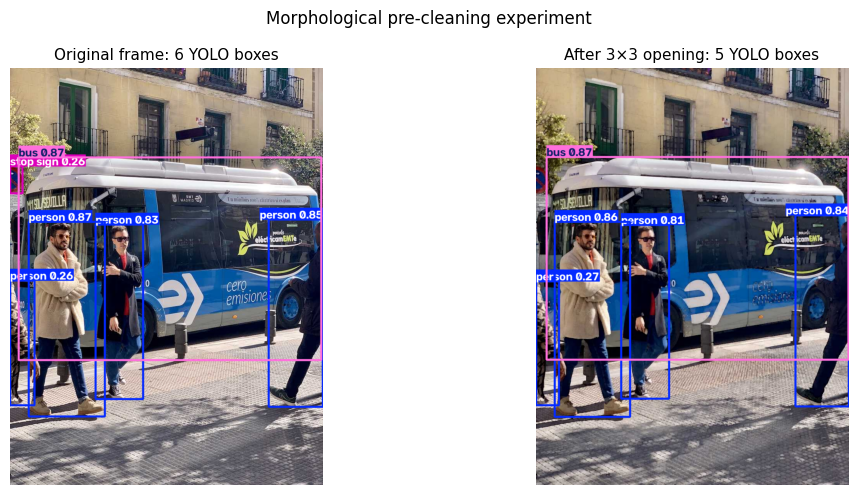

Detection count change: 6 -> 5
A lower or higher count alone does not prove better accuracy; inspect the boxes and image quality.


In [25]:
# Compare YOLO detections with and without a light 3x3 morphological opening.
# The operation is applied to the colour frame; this is only an experiment, not a guaranteed improvement.
clean_kernel = np.ones((3, 3), dtype=np.uint8)
cleaned_frame = cv2.morphologyEx(integrated_image, cv2.MORPH_OPEN, clean_kernel)

original_result = yolo_model.predict(integrated_image, conf=0.25, iou=0.5, verbose=False)[0]
cleaned_result = yolo_model.predict(cleaned_frame, conf=0.25, iou=0.5, verbose=False)[0]
original_count = 0 if original_result.boxes is None else len(original_result.boxes)
cleaned_count = 0 if cleaned_result.boxes is None else len(cleaned_result.boxes)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(original_result.plot(), cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Original frame: {original_count} YOLO boxes")
axes[1].imshow(cv2.cvtColor(cleaned_result.plot(), cv2.COLOR_BGR2RGB))
axes[1].set_title(f"After 3×3 opening: {cleaned_count} YOLO boxes")
for ax in axes:
    ax.axis("off")
plt.suptitle("Morphological pre-cleaning experiment")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "morphology_precleaning_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("Detection count change:", original_count, "->", cleaned_count)
print("A lower or higher count alone does not prove better accuracy; inspect the boxes and image quality.")

Morphology                :  2626.49 FPS  (0.04 seconds for 100 frames)
Bitwise + histogram       :  1205.67 FPS  (0.08 seconds for 100 frames)
YuNet face detector       :    81.27 FPS  (1.23 seconds for 100 frames)
YOLOv8n object detector   :     3.84 FPS  (26.06 seconds for 100 frames)
Combined YuNet + YOLO     :     5.09 FPS  (19.67 seconds for 100 frames)


,Technique,FPS
0,Morphology,2626.494607
1,Bitwise + histogram,1205.667893
2,YuNet face detector,81.267943
3,YOLOv8n object detector,3.837612
4,Combined YuNet + YOLO,5.085047


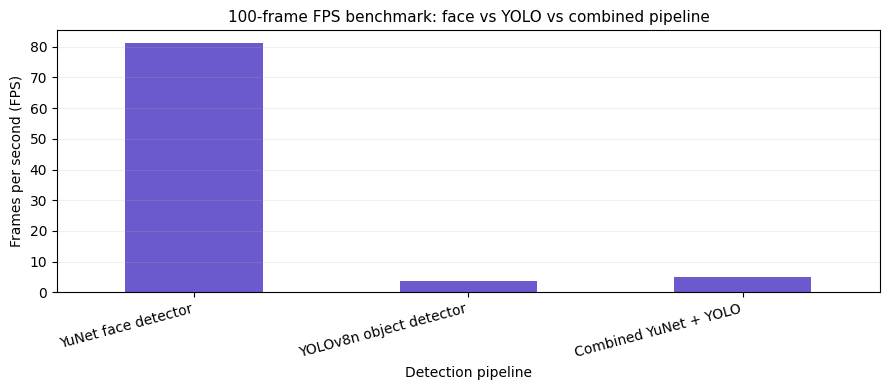

In [26]:
# Benchmark on the SAME 100-frame sample for each method.
# We cycle through the available sample photos to create 100 comparable frames.
# For a real deployment benchmark, replace this list with 100 consecutive webcam/video frames.
benchmark_names = [name for name in ["bus", "zidane", "lena"] if name in images]
if not benchmark_names:
    benchmark_names = [selected_name]

benchmark_base = [cv2.resize(images[name], (640, 480)) for name in benchmark_names]
benchmark_frames = [benchmark_base[index % len(benchmark_base)].copy() for index in range(100)]

# Build one detector used throughout the YuNet benchmark.
benchmark_yunet_detector = create_yunet_detector(score_threshold=0.7)


def measure_fps(function, frames):
    start = time.perf_counter()
    for frame in frames:
        function(frame)
    elapsed = time.perf_counter() - start
    return len(frames) / max(elapsed, 1e-9), elapsed


def morphology_benchmark(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    cv2.morphologyEx(gray, cv2.MORPH_OPEN, clean_kernel)


def bitwise_hist_benchmark(frame):
    h, w = frame.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, (w // 2, h // 2), min(h, w) // 3, 255, -1)
    cv2.bitwise_and(frame, frame, mask=mask)
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    cv2.calcHist([gray], [0], None, [256], [0, 256])


def yunet_benchmark(frame):
    detect_yunet_faces(frame, benchmark_yunet_detector)


def yolo_benchmark(frame):
    yolo_model.predict(frame, conf=0.25, iou=0.5, verbose=False)


def combined_benchmark(frame):
    integrated_detection(frame, benchmark_yunet_detector, confidence=0.25, iou=0.5)


benchmark_functions = {
    "Morphology": morphology_benchmark,
    "Bitwise + histogram": bitwise_hist_benchmark,
    "YuNet face detector": yunet_benchmark,
    "YOLOv8n object detector": yolo_benchmark,
    "Combined YuNet + YOLO": combined_benchmark,
}

fps_results = {}
for label, function in benchmark_functions.items():
    fps, elapsed = measure_fps(function, benchmark_frames)
    fps_results[label] = fps
    print(f"{label:26s}: {fps:8.2f} FPS  ({elapsed:.2f} seconds for 100 frames)")

fps_df = pd.DataFrame({"Technique": list(fps_results.keys()), "FPS": list(fps_results.values())})
display(fps_df)

# The required three-way detection benchmark chart.
detection_fps_df = fps_df[fps_df["Technique"].isin([
    "YuNet face detector", "YOLOv8n object detector", "Combined YuNet + YOLO"
])]
ax = detection_fps_df.plot(x="Technique", y="FPS", kind="bar", legend=False,
                           figsize=(9, 4), color="slateblue")
ax.set_title("100-frame FPS benchmark: face vs YOLO vs combined pipeline")
ax.set_xlabel("Detection pipeline")
ax.set_ylabel("Frames per second (FPS)")
ax.grid(axis="y", alpha=0.2)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "fps_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# Final comparison table. FPS is measured on the current computer above;
# bitwise/histogram and morphology are processing methods, not object detectors.
final_comparison = pd.DataFrame([
    {
        "Technique": "Morphology (opening/closing)",
        "Type": "Classical",
        "What it processes": "Binary foreground masks; removes specks or fills small gaps",
        "Lighting robustness": "Low by itself; depends on thresholding and image quality",
        "Approx. FPS": round(fps_results["Morphology"], 2),
        "Best use case": "Clean a mask before contours or measurement",
    },
    {
        "Technique": "Bitwise + histograms",
        "Type": "Classical",
        "What it processes": "Pixel masks/ROIs and image-intensity distributions",
        "Lighting robustness": "Histograms reveal lighting; bitwise masks do not detect objects",
        "Approx. FPS": round(fps_results["Bitwise + histogram"], 2),
        "Best use case": "ROI extraction, overlays, and exposure diagnostics",
    },
    {
        "Technique": "YuNet face detector",
        "Type": "Deep Learning (CNN)",
        "What it processes": "Human faces, bounding boxes, five landmarks, confidence",
        "Lighting robustness": "Moderate; can struggle with very dark, blurry, or occluded faces",
        "Approx. FPS": round(fps_results["YuNet face detector"], 2),
        "Best use case": "Lightweight face detection and privacy blur",
    },
    {
        "Technique": "YOLOv8n object detector",
        "Type": "Deep Learning",
        "What it processes": "80 COCO object classes, boxes, class labels, confidence",
        "Lighting robustness": "Moderate; depends on training data, scale, blur, and occlusion",
        "Approx. FPS": round(fps_results["YOLOv8n object detector"], 2),
        "Best use case": "Fast multi-class object detection on CPU/edge devices",
    },
])

display(final_comparison)
final_comparison.to_csv(PLOTS_DIR / "final_comparison_table.csv", index=False)

,Technique,Type,What it processes,Lighting robustness,Approx. FPS,Best use case
0,Morphology (opening/closing),Classical,Binary foreground masks; removes specks or fil...,Low by itself; depends on thresholding and ima...,2626.49,Clean a mask before contours or measurement
1,Bitwise + histograms,Classical,Pixel masks/ROIs and image-intensity distribut...,Histograms reveal lighting; bitwise masks do n...,1205.67,"ROI extraction, overlays, and exposure diagnos..."
2,YuNet face detector,Deep Learning (CNN),"Human faces, bounding boxes, five landmarks, c...","Moderate; can struggle with very dark, blurry,...",81.27,Lightweight face detection and privacy blur
3,YOLOv8n object detector,Deep Learning,"80 COCO object classes, boxes, class labels, c...","Moderate; depends on training data, scale, blu...",3.84,Fast multi-class object detection on CPU/edge ...


### Task 5.5 — Final reflection

For a real-time monitoring system, a practical starting combination is **light classical pre-processing only when it improves the camera image, YuNet for faces, and YOLOv8n for general objects**. YuNet is specialised for faces, while YOLO detects multiple COCO object categories. The measured FPS chart helps show the compute cost of running each detector separately and together.

For a **low-power edge device**, keep the pipeline small: use YOLOv8n, use a moderate YuNet threshold, resize frames to a sensible resolution, and avoid unnecessary pre-processing. Only keep morphology when it measurably reduces noise without damaging the objects. For a **cloud server**, a larger YOLO model such as `yolov8s` can be tested when higher accuracy matters more than speed; tune it on representative data and compare actual latency and detection quality.

**Important conclusion:** Higher FPS does not automatically mean higher accuracy. Compare missed detections, false positives, lighting, occlusion, and actual camera conditions before choosing a production configuration. The FPS numbers in this notebook are measured on the computer where it is run, so your numbers will differ from another laptop or GPU.

## Optional integrated webcam demo

Run this on a local computer with a webcam and OpenCV GUI support. It shows YuNet faces in **green** and YOLO object detections in **red** on the same live frame. In Google Colab or a headless environment, use the static-image pipeline or a recorded video file instead.

In [28]:
def run_integrated_webcam(max_seconds=20):
    detector = create_yunet_detector(score_threshold=0.7)
    camera = cv2.VideoCapture(0)
    if not camera.isOpened():
        print("Webcam not available. Skipping integrated live demo.")
        return None

    frame_count = 0
    start_time = time.perf_counter()
    print("Press q to stop the webcam window.")
    try:
        while time.perf_counter() - start_time < max_seconds:
            ok, frame = camera.read()
            if not ok:
                break
            output, face_count, object_count = integrated_detection(frame, detector)
            frame_count += 1
            elapsed = max(time.perf_counter() - start_time, 1e-6)
            fps = frame_count / elapsed
            cv2.putText(output, f"FPS: {fps:.1f} | Faces: {face_count} | Objects: {object_count}",
                        (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 0), 2)
            cv2.imshow("Integrated YuNet + YOLO — press q to quit", output)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    except cv2.error as error:
        print("OpenCV display is not supported in this notebook environment:", error)
    finally:
        camera.release()
        cv2.destroyAllWindows()

    elapsed = max(time.perf_counter() - start_time, 1e-6)
    fps = frame_count / elapsed
    print(f"Combined webcam pipeline: {frame_count} frames in {elapsed:.2f}s = {fps:.2f} FPS")
    return fps

RUN_INTEGRATED_WEBCAM = False
if RUN_INTEGRATED_WEBCAM:
    integrated_webcam_fps = run_integrated_webcam(max_seconds=20)
else:
    print("Set RUN_INTEGRATED_WEBCAM = True to run the live combined demo.")

Set RUN_INTEGRATED_WEBCAM = True to run the live combined demo.
